# Markov Chains: Transition and Simulation

## Introduction

- A **stochastic process** is a random phenomenon that changes over time.
- Our workhorse model is the **Empirical Markov chain**: the distribution of the next state depends on the current state.
- Last week, we touched on the core ideas by reviewing joint, marginal, and conditional probability mass functions
- This week, we want to take those concepts as given, and explore the Markov concept more deeply

## Outline

We have three big ideas that build on last week:

1. Sequences and the State Space
2. The Transition Matrix
3. Simulating a Chain

I'll work with data about Bach chorales, and you'll work with data about taxicab trajectories

# 1. Sequences and the State Space

## Sequences

- A **sequence** is a collection of values ordered by a time or position index.
- Stock prices are indexed by time; a melody is a sequence of notes; text is a sequence of tokens.
- A chorale is a sequence of chords. A taxicab trajectory is a sequence of recorded neighborhoods.
- A stochastic process $\{X_t\}_{t=0}^{T-1}$ models uncertainty about these values and how they jointly evolve over time.

Our data contain **many separate sequences**. The last chord of one chorale does not lead to the first chord of the next. The same rule applies to separate cab trajectories.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Bach and chords

- Music is sound in time. 
- A chord is a set of notes played at the same time.
- Music can be studied and understood **harmonically** as the sequence of chord progressions/changes.
- What chords occur, and how do they evolve from one to another? 

In [3]:
columns = (['song', 'time'] + 
           [str(i) for i in range(1, 13)] + 
           ['root', 'what', 'chord'])


bach_df = pd.read_csv( './data/bach.data',
                       header=None, names=columns)

# Convert symbols for music21
for old, new in [(' ', ''), ('_', ''), ('M', ''), ('b', '-'),
                 ('d', 'dim'), ('dim6', 'dim'), ('m4', 'm')]:
    bach_df['chord'] = bach_df['chord'].str.replace(old, new, regex=False)

bach_df.head()

,song,time,1,2,3,4,5,6,7,8,9,10,11,12,root,what,chord
0,000106b_,1,YES,NO,NO,NO,NO,YES,NO,NO,NO,YES,NO,NO,F,3,F
1,000106b_,2,YES,NO,NO,NO,YES,NO,NO,YES,NO,NO,NO,NO,E,5,C
2,000106b_,3,YES,NO,NO,NO,YES,NO,NO,YES,NO,NO,NO,NO,E,2,C
3,000106b_,4,YES,NO,NO,NO,NO,YES,NO,NO,NO,YES,NO,NO,F,3,F
4,000106b_,5,YES,NO,NO,NO,NO,YES,NO,NO,NO,YES,NO,NO,F,2,F


In [4]:
bach_sequences = [
    song.sort_values('time')['chord'].tolist()
    for _, song in bach_df.groupby('song', sort=False)
]

bach_states = sorted({chord for song in bach_sequences for chord in song})

display(bach_df.head(10))
print(f'{len(bach_sequences):,} chorales; {len(bach_df):,} chord observations; '
      f'{len(bach_states):,} distinct chord states')
print('One chorale:', bach_sequences[5][:25])

,song,time,1,2,3,4,5,6,7,8,9,10,11,12,root,what,chord
0,000106b_,1,YES,NO,NO,NO,NO,YES,NO,NO,NO,YES,NO,NO,F,3,F
1,000106b_,2,YES,NO,NO,NO,YES,NO,NO,YES,NO,NO,NO,NO,E,5,C
2,000106b_,3,YES,NO,NO,NO,YES,NO,NO,YES,NO,NO,NO,NO,E,2,C
3,000106b_,4,YES,NO,NO,NO,NO,YES,NO,NO,NO,YES,NO,NO,F,3,F
4,000106b_,5,YES,NO,NO,NO,NO,YES,NO,NO,NO,YES,NO,NO,F,2,F
5,000106b_,6,NO,NO,YES,NO,NO,YES,NO,NO,NO,YES,NO,NO,D,4,Dm
6,000106b_,7,NO,NO,YES,NO,NO,YES,NO,NO,NO,YES,NO,NO,D,2,Dm
7,000106b_,8,YES,NO,NO,NO,NO,YES,NO,NO,NO,YES,NO,NO,A,3,F
8,000106b_,9,YES,NO,NO,NO,NO,YES,NO,NO,NO,YES,NO,NO,A,2,F
9,000106b_,10,NO,NO,YES,NO,NO,YES,NO,NO,NO,NO,YES,NO,Bb,5,B-


62 chorales; 5,665 chord observations; 99 distinct chord states
One chorale: ['Gm', 'Gm', 'Gm', 'Gm7', 'Cm', 'Cm7', 'D', 'D7', 'Gm', 'D7', 'Gm', 'Cm7', 'D', 'D', 'Gm', 'Gm', 'F', 'F', 'F', 'B-', 'B-', 'Gm', 'Gm7', 'Cm', 'Cm']


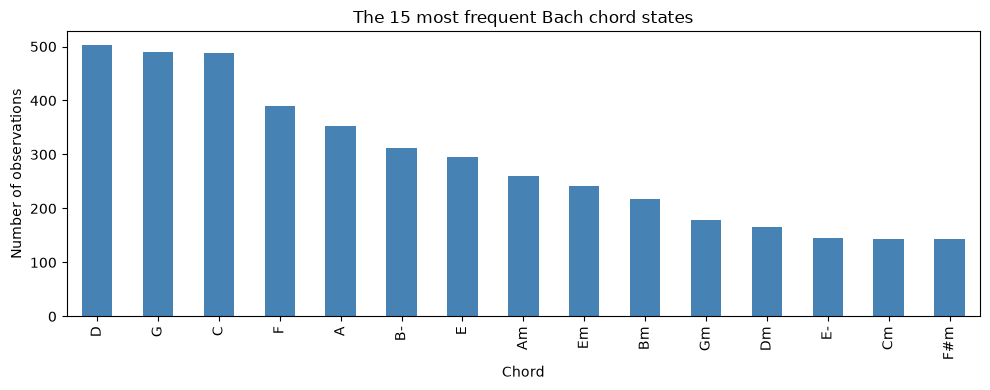

In [5]:
chord_counts = bach_df['chord'].value_counts()
fig, ax = plt.subplots(figsize=(10, 4))
chord_counts.head(15).plot.bar(ax=ax, color='steelblue')
ax.set(title='The 15 most frequent Bach chord states',
       xlabel='Chord', ylabel='Number of observations')
fig.tight_layout()
plt.show()

## States
- A **state** is an irreducible and complete representation of the system
- In the Bach case (from a harmonic perspective), the **state space** is the set of all chords that appear in the corpus of chorales
- For stock prices, it could be a price; for a patient, it could be heart rate; and so on
- The state space is the fundamental concept for Markov chains: We then put a conditional mass function over transitions across the state sapce

## Exercise 1: taxicab trajectories

- `taxicab.pkl` contains a list of 1,000 cab-days, each holding a sequence of neighborhood labels. 
- The values are the states; the repeated integer indices are neighborhood codes, not timestamps. 
- Load the data and determine the state space.

In [6]:
!wget -q --show-progress -O taxicab.pkl \
"https://huggingface.co/datasets/ds4e/taxicab/resolve/main/taxicab.pkl"

'wget' is not recognized as an internal or external command,
operable program or batch file.


In [7]:
taxicab_raw = pd.read_pickle('data/taxicab.pkl')

print(f'Trajectories: {len(taxicab_raw):,}')
print(f'Total recorded observations: {sum(len(trajectory) for trajectory in taxicab_raw):,}')
print('First trajectory (index = neighborhood code):')
display(taxicab_raw[0].head(12))

# .tolist() extracts values in their existing order, without aligning Series indices.
example_trajectory = taxicab_raw[0].iloc[:12].tolist()
print('Values in sequence order:', example_trajectory)

Trajectories: 1,000
Total recorded observations: 22,963,396
First trajectory (index = neighborhood code):


0     Outside Manhattan
0     Outside Manhattan
0     Outside Manhattan
0     Outside Manhattan
0     Outside Manhattan
0     Outside Manhattan
0     Outside Manhattan
2          Central Park
2          Central Park
34      Upper East Side
34      Upper East Side
35      Upper West Side
Name: nbhd, dtype: object

Values in sequence order: ['Outside Manhattan', 'Outside Manhattan', 'Outside Manhattan', 'Outside Manhattan', 'Outside Manhattan', 'Outside Manhattan', 'Outside Manhattan', 'Central Park', 'Central Park', 'Upper East Side', 'Upper East Side', 'Upper West Side']


In [8]:
import pickle

path = 'data/taxicab.pkl'

with open(path, 'rb') as file: # rb = read binary
    raw = pickle.load(file)

print(f'Example: {raw[0]}')
print(f'Number of trajectories: {len(raw):,}')
print(f'Total recorded observations: {sum(len(trajectory) for trajectory in raw):,}')


Example: 0     Outside Manhattan
0     Outside Manhattan
0     Outside Manhattan
0     Outside Manhattan
0     Outside Manhattan
            ...        
29                 SoHo
29                 SoHo
13    Greenwich Village
3               Chelsea
3               Chelsea
Name: nbhd, Length: 26026, dtype: object
Number of trajectories: 1,000
Total recorded observations: 22,963,396


In [9]:
# Exercise 1: your inspection and preparation here.
# Keep the outer list: each entry is a separate trajectory or uninterrupted segment.
# taxicab_sequences = ...
# taxicab_states = ...

states = set() 
for trip in raw:
    states = states.union(set(trip))

states

{'Battery Park City',
 'Central Park',
 'Chelsea',
 'Chinatown',
 'Civic Center',
 'East Harlem',
 'East Village',
 'Ellis Island',
 'Financial District',
 'Flatiron District',
 'Governors Island',
 'Gramercy',
 'Greenwich Village',
 'Harlem',
 "Hell's Kitchen",
 'Inwood',
 'Kips Bay',
 'Liberty Island',
 'Little Italy',
 'Lower East Side',
 'Marble Hill',
 'Midtown',
 'Morningside Heights',
 'Murray Hill',
 'NoHo',
 'Nolita',
 'Outside Manhattan',
 "Randall's Island",
 'Roosevelt Island',
 'SoHo',
 'Stuyvesant Town',
 'Theater District',
 'Tribeca',
 'Two Bridges',
 'Upper East Side',
 'Upper West Side',
 'Washington Heights',
 'West Village'}

In [10]:

list(states)
len(states)

38

set is unordered collection, does not keep track of frequencies. we are just smashing data into only unique states.


# 2. The Transition Matrix

## The Transition Matrix
- Once you have a state space, we can imagine changes over that space over time
- Using the expansion trick, we can focus on order-1 transitions over a finite state space
- Then we can capture the system's behavior in a matrix where
    - Each row corresponds to a current state
    - Each column corresponds to a future state
    - The intersection is the probability of the transition


## Moving from state to state

- For states $i$ and $j$, count observed transitions **within** each sequence:
$$
P_{i \rightarrow j} = \dfrac{\frac{1}{T} \sum_{t=0}^{T-1} \mathbb{I}\{ X_{t+1}=j, X_{t}=i\}}{\frac{1}{T} \sum_{t=0}^{T-1} \mathbb{I}\{X_{t}=i\}} = \dfrac{\text{Proportion of transitions from $i$ to $j$}}{\text{Proportion of observations in state $i$}}
$$

- This is called the **transition matrix**, $P$
- Each row $i$ corresponds to a state; each $P_{ij}$ is the probability of transition from $i$ to $j$
- We are estimating a conditional probability,
$$
\text{pr}[X_{t+1}=j | X_t = i] = \dfrac{\text{pr}[X_{t+1}=j \text{ and } X_t = i]}{\text{pr}[ X_t = i]} = \dfrac{\text{joint}}{\text{marginal}}
$$


## Computation
- Last week, we used Pandas, but our data now are variable length sequences
- The next code chunk gives code to get the transition counts, and then normalize to get the probabilities
- When transitions are **sparse**, this can require significant thought

In [11]:
## Basic Approach

# Transition dictionary:
state_index = {state: i for i, state in enumerate(bach_states)}

# Compute counts:
counts = np.zeros((len(bach_states), len(bach_states)), dtype=np.int32)
for song in bach_sequences:
    indices = np.array([state_index[state] for state in song], dtype=int)
    np.add.at(counts, (indices[:-1], indices[1:]), 1) # Vectorized pairwise counting

# Compute transition probabilities:
bach_P = counts / counts.sum(axis=1)[:, None] # Transition matrix

In [12]:
## Breaking the task into functions, with more guardrails

def transition_counts(sequences, states):
    state_index = {state: i for i, state in enumerate(states)}
    counts = np.zeros((len(states), len(states)), dtype=np.int64)
    for sequence in sequences:
        indices = np.array([state_index[state] for state in sequence], dtype=int)
        np.add.at(counts, (indices[:-1], indices[1:]), 1)
    return counts

def transition_probabilities(counts):
    margin = counts.sum(axis=1, keepdims=True)
    return np.divide(counts, margin,
                     out=np.zeros_like(counts, dtype=float), where=margin != 0)

In [13]:
bach_counts = transition_counts(bach_sequences, bach_states)
bach_P = transition_probabilities(bach_counts)

In [14]:
# First seven rows/columns
common_chords = chord_counts.head(7).index.tolist()
bach_P_df = pd.DataFrame(bach_P, index=bach_states, columns=bach_states)
display(bach_P_df.loc[common_chords, common_chords].round(3))

,D,G,C,F,A,B-,E
D,0.444,0.186,0.016,0.004,0.073,0.002,0.026
G,0.103,0.458,0.211,0.008,0.006,0.002,0.010
C,0.035,0.127,0.504,0.122,0.006,0.004,0.010
F,0.013,0.021,0.120,0.470,0.000,0.180,0.000
A,0.219,0.009,0.006,0.003,0.461,0.000,0.064
B-,0.023,0.003,0.026,0.127,0.000,0.519,0.003
E,0.004,0.000,0.004,0.018,0.179,0.000,0.418


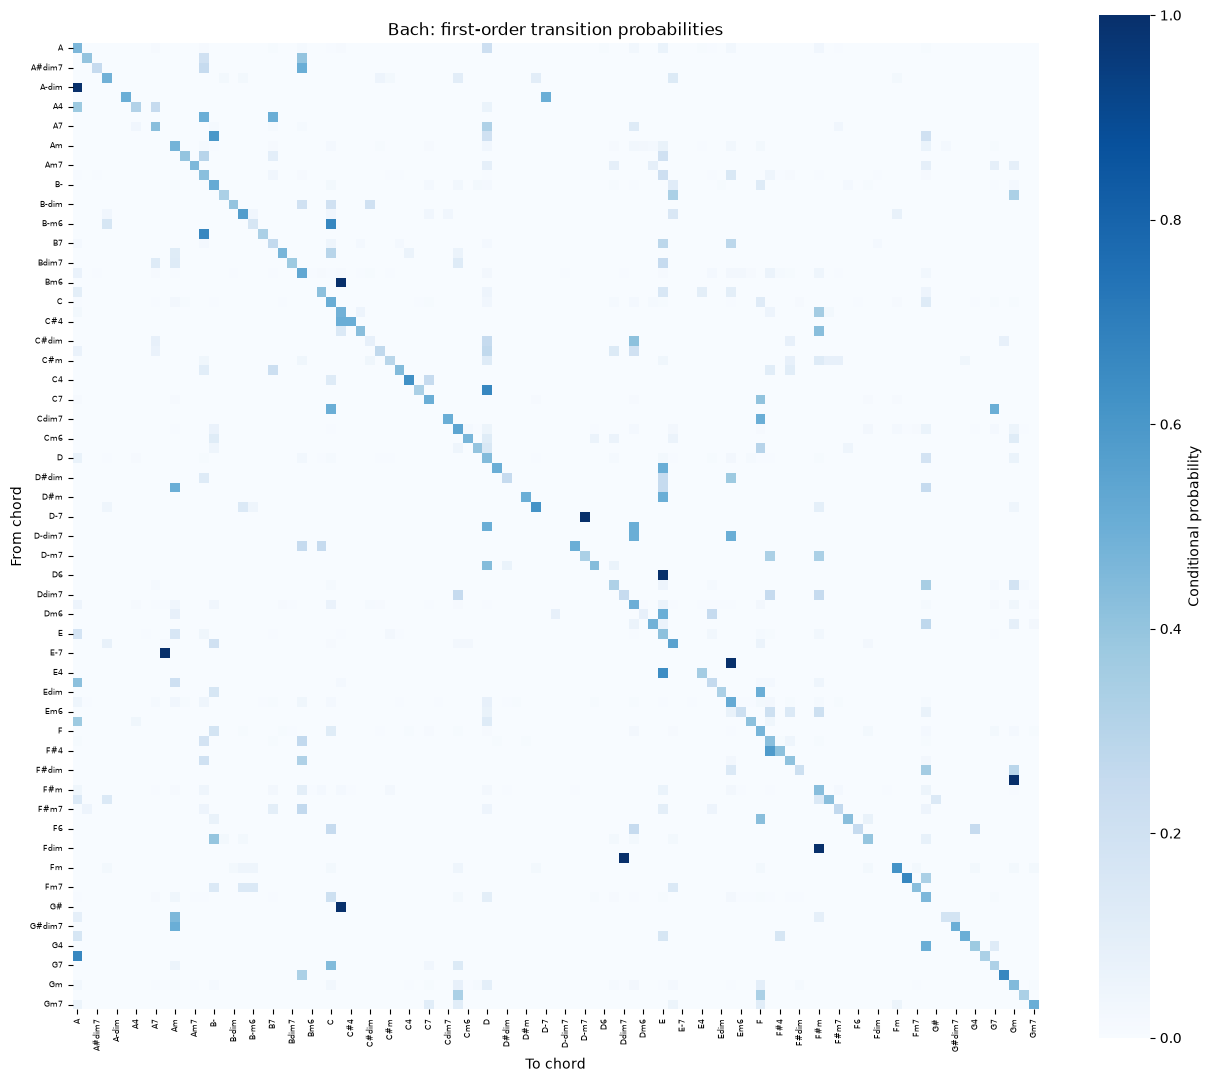

In [15]:
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(bach_P_df, cmap='Blues', square=True,
            cbar_kws={'label': 'Conditional probability'}, ax=ax)
ax.set(title='Bach: first-order transition probabilities',
       xlabel='To chord', ylabel='From chord')
ax.tick_params(axis='x', labelrotation=90, labelsize=6)
ax.tick_params(axis='y', labelrotation=0, labelsize=6)
fig.tight_layout()
plt.show()

Dark blue are overfitted - transition probability that high likely because that transition is rare in the dataset

## Exercise 2: estimate taxicab transitions

1. Use your prepared sequences to compute `taxicab_counts` and `taxicab_P` with the same row transition convention as Bach.
2. Plot a labeled heatmap. Compare the routes with the largest **counts** with destinations having the largest **conditional probabilities** from a selected origin. Report how many observations support each claim.

In [35]:
# Exercise 2: counts, row checks, heatmap, and route comparisons here.
## Basic Approach
taxicab_states = list(states)

counts = np.zeros((len(states), len(states)))

state_index = {}
for i, s in enumerate(taxicab_states): # dictionary with all neighborhoods as keys and position in list as value
    state_index[s] = i 

# count the transitions. counts [i, j] = number of times i was followed by j
taxicab_counts = np.zeros((len(states), len(states))) # intializing empty grid of 0s that loop below will fill in

for trip in raw: # one cab day at a time
    trip = trip.tolist() # just neighborhoods in order
    for t in range(len(trip) - 1): # stop one early because the last stop doesn't have a next
        here = state_index[trip[t]] # store where the cab is now as row
        nxt = state_index[trip[t+1]] #  store where cab goes next as column
        taxicab_counts[here, nxt] += 1 # tally that transition so we can calculate probabilities later


In [32]:
# turning the above counts into probabilities
taxicab_P = np.zeros((len(states), len(states)))
for i in range(len(states)):
    row_total = taxicab_counts[i].sum() # how many times cab LEFT neighborhod i
    if row_total > 0: # skip neighborhoods with no departures
        taxicab_P[i] = taxicab_counts[i] / row_total

In [34]:
print(taxicab_counts.sum())
print(taxicab_P.sum(axis=1)[:10]) # each row should be 1 (conditional probs sum to 1) or 0 if no departures

22962396.0
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


each row is a conditional distribution: each entry is probability = probability of next location given current location. these conditional probs sum to 1

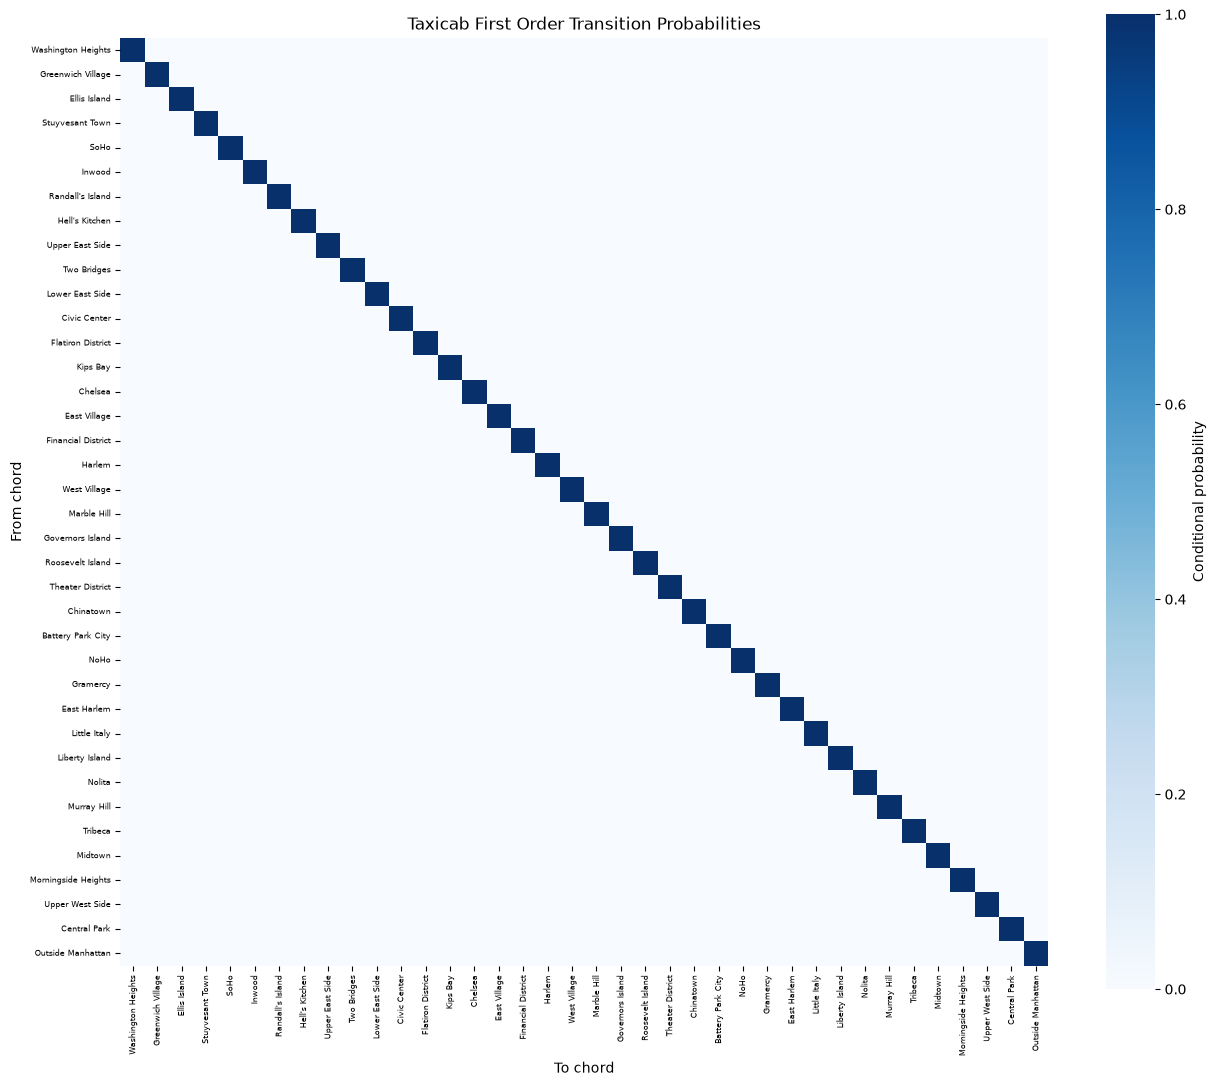

In [40]:
# heatmap

taxicab_P_df = pd.DataFrame(taxicab_P, index=taxicab_states, columns=taxicab_states)
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(taxicab_P_df, cmap='Blues', square=True,
            cbar_kws={'label': 'Conditional probability'}, ax=ax)
ax.set(title='Taxicab First Order Transition Probabilities',
       xlabel='To chord', ylabel='From chord')
ax.tick_params(axis='x', labelrotation=90, labelsize=6)
ax.tick_params(axis='y', labelrotation=0, labelsize=6)
fig.tight_layout()
plt.show()

## The Order of a Chain
- In many systems, a naive definition of state can be misleading
- In a song, the sequence of chords typically exhibits dependence over more than one change: A common progression is I-V-vi-IV, for example
- In that case, we **expand the state space** and represent the state as a tuple, so the sequence `C → Am → Dm → G` becomes `(C, Am) → (Am, Dm) → (Dm, G)`.
- The number of lagged values included is called the **order** of the chain
- If the original state space has $K$ elements, then the order $O$ expansion has $K^O$ elements: This is a curse of dimensionality 
- The transformer is a way to address the curse of dimensionality with sequences with high order dependence on previous values

In [17]:
## Convert to pairwise transitions
bach_pair_sequences = [
    list(
        zip(song[:-1], song[1:])
    ) for song in bach_sequences
]
## Compute counts and probabilities for pairwise transitions
bach_pair_states = sorted({pair for song in bach_pair_sequences for pair in song})
bach_pair_counts = transition_counts(bach_pair_sequences, bach_pair_states)
bach_pair_P = transition_probabilities(bach_pair_counts)

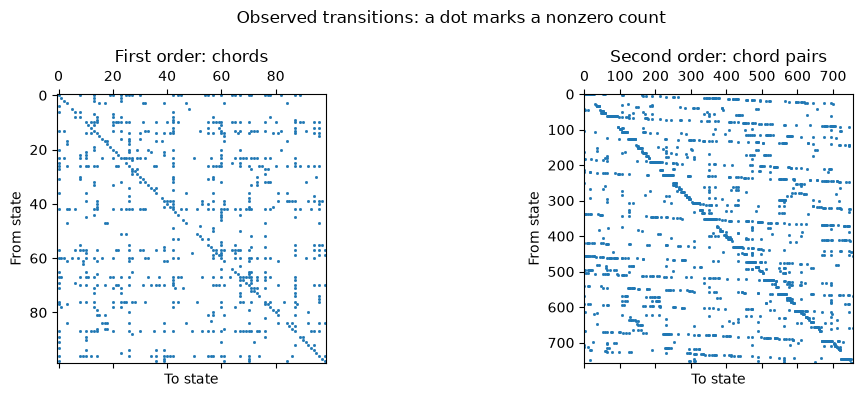

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, counts, title in zip(axes, [bach_counts, bach_pair_counts],
                              ['First order: chords', 'Second order: chord pairs']):
    ax.spy(counts, markersize=1)
    ax.set(title=title, xlabel='To state', ylabel='From state')
fig.suptitle('Observed transitions: a dot marks a nonzero count')
fig.tight_layout()
plt.show()

## Connectivity

- A chain is **strongly connected** or **irreducible** if every state can reach every other state along a path of positive-probability transitions
- The transition matrix might have indirect paths from states to states, and the bigger the state space, the more indirect paths are possible
- If chains have disconnected components, activity remains confined to them once the chain reachs them
- There are many long-run patterns of behavior as there are disconnected components

In [19]:
import networkx as nx

for name, counts in [('Bach chords', bach_counts), ('Bach chord pairs', bach_pair_counts)]:
    graph = nx.from_numpy_array(counts > 0, create_using=nx.DiGraph)
    components = list(nx.strongly_connected_components(graph))
    print(f'{name}: strongly connected = {nx.is_strongly_connected(graph)}; '
          f'components = {len(components)}; '
          f'largest component = {max(map(len, components))} states')

Bach chords: strongly connected = True; components = 1; largest component = 99 states
Bach chord pairs: strongly connected = False; components = 15; largest component = 743 states


## Exercise 3: memory and connectivity in taxicab data

1. Is the current neighborhood enough to predict the next one? Give reasons a previous neighborhood, time of day, or driver behavior might matter. First order is a modeling assumption to assess.
2. Optional: Construct the directed graph of your observed transitions. Is it strongly connected? If not, identify the components and any states without departures. The `G=nx.DiGraph(...)` and `nx.draw(G,...)` can do this for you.
3. Optional: estimate a second-order model on a subset of trajectories. Compare its number of states, sparsity, and counts per state with the first-order model. How would you check whether the extra memory improves prediction on held-out trajectories?

In [20]:
# Exercise 3: connectivity and evidence about memory here.

# 3. Simulation

## Simulation

With the state space and transition matrix, we have everything we need to simulate the chain:

1. Pick an initial state.
2. Each row of `bach_P` gives the probabilities of the next chord, conditional on the current chord. Draw from that row, move to the new state.
3. Repeat step 2.

In [21]:
def simulate(states, probabilities, initial_state, n_steps, seed=100):
    rng = np.random.default_rng(seed)
    index = states.index(initial_state)
    path = [initial_state]
    for _ in range(n_steps):
        outgoing = probabilities[index]
        if outgoing.sum() == 0:
            print(f'No observed departures from {states[index]!r}; stopping.')
            break
        index = rng.choice(len(states), p=outgoing)
        path.append(states[index])
    return path

In [22]:
bach_simulation = simulate(bach_states, bach_P, initial_state='C', n_steps=20)
rng = np.random.default_rng(100)
independent_chords = rng.choice(
    bach_states, size=21,
    p=chord_counts.reindex(bach_states).to_numpy() / chord_counts.sum(),
).tolist()
print('Independent chords:', ' → '.join(independent_chords))
print('First-order chain:', ' → '.join(bach_simulation))

Independent chords: F#m → E → C → A → Gm → E → F# → G → Em → B- → Gm → C → E → E → E → D7 → Gm → D → F → D → Gm7
First-order chain: C → F6 → F6 → Dm → A → F#m → F#m → F#m → F#m7 → F#m7 → B7 → Fdim → F#m → F#m → F#m → F#m → F#m → Gm → F → F → F


## Exercise 4: Simulate taxicab locations

1. Choose any neighborhood and simulate the first 10 transitions using your Markov chain. 
2. Repeat step 1, for 100 transitions, caching the final result.
3. Repeat step 2 five hundred times, and plot the probability mass function over neighborhoods. 
4. Choose any neighborhood and repeat the above. Compare the probability mass functions. Are they similar or significantly different?

In [23]:
# Exercise 4: simulation, forecasts, and interpretation here.